# VisA defect classification with ResNet-18

Train a binary classifier on candle images using the official VisA two-class high-shot split. The pretrained ResNet-18 stays frozen while its new final layer learns to predict defects. This supervised run uses all labels in the training split.

[Open in Colab](https://colab.research.google.com/github/Brafied/defect-detection-active-learning/blob/resnet18-baseline/visa_resnet18_baseline.ipynb)

Run all cells in order. The last two cells display the check-in figures and export them to `results/candle_resnet18/`.

### 1. Load the candle split

The first run downloads the [VisA archive](https://github.com/amazon-science/spot-diff) (about 1.9 GB) and extracts the selected product. Rerunning these cells reuses the local images. A Colab GPU is optional.

In [1]:
import csv
from pathlib import Path
import subprocess

item = "candle"
data_dir = Path("visa_data")
data_dir.mkdir(exist_ok=True)
split_file = data_dir / "2cls_highshot.csv"
archive = data_dir / "VisA_20220922.tar"

def download(url, destination):
    if destination.is_file():
        return
    partial = destination.with_suffix(destination.suffix + ".part")
    subprocess.run(["curl", "--fail", "--location", "--retry", "2", "--output", str(partial), url], check=True)
    partial.replace(destination)

download("https://raw.githubusercontent.com/amazon-science/spot-diff/main/split_csv/2cls_highshot.csv", split_file)
with split_file.open(newline="") as file:
    rows = [row for row in csv.DictReader(file) if row["object"] == item]


### 2. Prepare the images and model

In [2]:
import torch
from PIL import Image
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision.models import ResNet18_Weights, resnet18

torch.set_num_threads(3)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()

class VisaDatasetSplit(Dataset):
    def __init__(self, split):
        self.examples = [row for row in rows if row["split"] == split]

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        row = self.examples[index]
        with Image.open(data_dir / row["image"]) as image:
            pixels = preprocess(image.convert("RGB"))
        label = torch.tensor({"normal": 0, "anomaly": 1}[row["label"]], dtype=torch.float32)
        return pixels, label

training_split = VisaDatasetSplit("train")
testing_split = VisaDatasetSplit("test")
print(f"{item}: {len(training_split)} training and {len(testing_split)} test images")

candle: 660 training and 440 test images


In [3]:
model = resnet18(weights=weights)
model.requires_grad_(False)
model.fc = nn.Linear(model.fc.in_features, 1)
model.to(device)
# Keep the frozen backbone's batch normalization statistics fixed during training.
model.eval()

loss_function = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.fc.parameters(), lr=1e-5, weight_decay=1e-4)

### 3. Train the binary classifier
The frozen encoder and deterministic image transforms give each candle the same features every epoch. Compute these features once, then fit the final layer for 10 epochs. The fixed defect cutoff is 0.5.

In [4]:
encoder = nn.Sequential(*list(model.children())[:-1], nn.Flatten()).eval()

@torch.no_grad()
def extract_features(dataset):
    vectors, labels = [], []
    for start in range(0, len(dataset), 16):
        batch = [dataset[i] for i in range(start, min(start + 16, len(dataset)))]
        images, targets = zip(*batch)
        vectors.append(encoder(torch.stack(images).to(device)).cpu())
        labels.append(torch.stack(targets))
    return TensorDataset(torch.cat(vectors), torch.cat(labels))

training_loader = DataLoader(extract_features(training_split), batch_size=16, shuffle=True)
testing_loader = DataLoader(extract_features(testing_split), batch_size=16, shuffle=False)

In [5]:
import pandas as pd
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score

epoch_metrics = []
for epoch in range(1, 11):
    total_loss = 0.0
    for features, labels in training_loader:
        optimizer.zero_grad()
        logits = model.fc(features.to(device)).squeeze(1)
        loss = loss_function(logits, labels.to(device))
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)

    probabilities, actual = [], []
    with torch.no_grad():
        for features, labels in testing_loader:
            logits = model.fc(features.to(device)).squeeze(1)
            probabilities.extend(logits.sigmoid().cpu().tolist())
            actual.extend(labels.int().tolist())

    predicted = [int(p >= 0.5) for p in probabilities]
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    epoch_metrics.append(dict(
        epoch=epoch, train_loss=total_loss / len(training_split), accuracy=(tn + tp) / len(actual),
        average_precision=average_precision_score(actual, probabilities),
        roc_auc=roc_auc_score(actual, probabilities), tn=tn, fp=fp, fn=fn, tp=tp,
        precision=tp / (tp + fp) if tp + fp else None, recall=tp / (tp + fn),
        f1=2 * tp / (2 * tp + fp + fn)
    ))
    print(f"Epoch {epoch:2d} | train loss {epoch_metrics[-1]['train_loss']:.4f} | "
          f"test accuracy {epoch_metrics[-1]['accuracy']:.4f}")

Epoch  1 | train loss 0.4340 | test accuracy 0.9091
Epoch  2 | train loss 0.4089 | test accuracy 0.9091
Epoch  3 | train loss 0.3891 | test accuracy 0.9091
Epoch  4 | train loss 0.3735 | test accuracy 0.9091
Epoch  5 | train loss 0.3604 | test accuracy 0.9091
Epoch  6 | train loss 0.3500 | test accuracy 0.9091
Epoch  7 | train loss 0.3415 | test accuracy 0.9091


Epoch  8 | train loss 0.3348 | test accuracy 0.9091
Epoch  9 | train loss 0.3295 | test accuracy 0.9091
Epoch 10 | train loss 0.3253 | test accuracy 0.9091


### 4. Save the results and display the check-in figures
Both figures use the training history and test predictions from the cells above. The notebook displays the same PNG files it saves for the report.

In [6]:
from IPython.display import Image as NotebookImage, display
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

folder = Path("results/candle_resnet18")
folder.mkdir(parents=True, exist_ok=True)
history = pd.DataFrame(epoch_metrics)
pred = pd.DataFrame({"image": [row["image"] for row in testing_split.examples],
                     "label": actual, "probability": probabilities, "prediction": predicted})
history.to_csv(folder / "epoch_metrics.csv", index=False)
pred.to_csv(folder / "test_predictions.csv", index=False)
y, score = pred.label, pred.probability
matrix = confusion_matrix(y, pred.prediction, labels=[0, 1])
ap, auc = history.iloc[-1][["average_precision", "roc_auc"]]
blue, green, gray = "#1c5282", "#16705f", "#647681"

def display_figure(fig, filename):
    path = folder / filename
    fig.savefig(path, dpi=220, facecolor="white")
    plt.close(fig)
    display(NotebookImage(filename=str(path), width=770))

display(history.tail(1).round(4))

,epoch,train_loss,accuracy,average_precision,roc_auc,tn,fp,fn,tp,precision,recall,f1
9,10,0.3253,0.9091,0.0878,0.4441,400,0,40,0,None,0.0,0.0


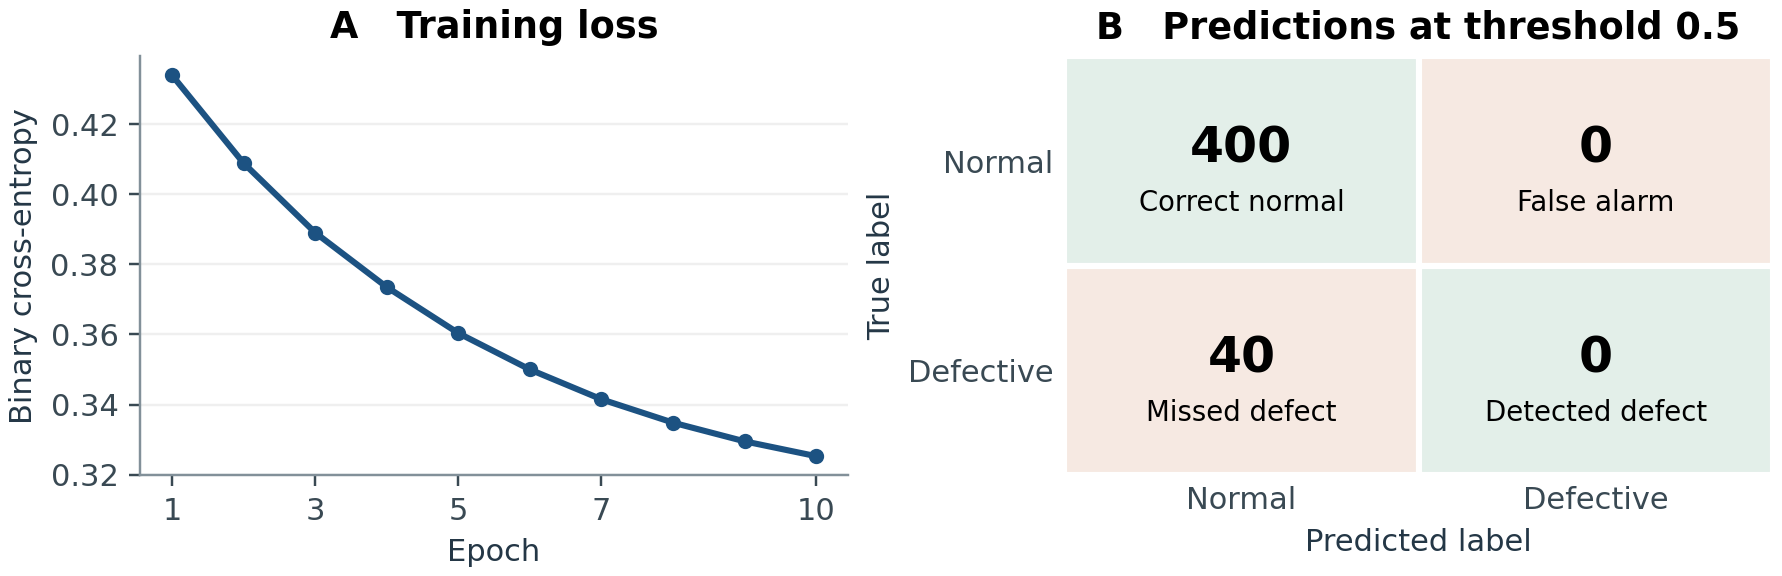

In [7]:
# Figure 1: Training loss and test decisions
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"axes.spines.right":False,
                     "axes.spines.top":False,"axes.titleweight":"bold","axes.labelcolor":"#243746",
                     "axes.edgecolor":"#829099","xtick.color":"#394953","ytick.color":"#394953"})
fig, (loss, cm) = plt.subplots(1, 2, figsize=(8.1,2.62), layout="constrained")
loss.plot(history.epoch,history.train_loss,marker="o",ms=4,color=blue,lw=2)
loss.set(title="A   Training loss", xlabel="Epoch", ylabel="Binary cross-entropy", xticks=[1,3,5,7,10])
loss.grid(axis="y",alpha=.2)
tn,fp,fn,tp = matrix.ravel()
labels = [["Correct normal","False alarm"],["Missed defect","Detected defect"]]
cm.set_xlim(0,2); cm.set_ylim(2,0); cm.set_xticks([.5,1.5],["Normal","Defective"]); cm.set_yticks([.5,1.5],["Normal","Defective"]); cm.set_xlabel("Predicted label"); cm.set_ylabel("True label"); cm.set_title("B   Predictions at threshold 0.5")
for s in cm.spines.values(): s.set_visible(False)
cm.tick_params(length=0)
for i in range(2):
    for j in range(2):
        cm.add_patch(plt.Rectangle((j,i),1,1,fc="#e3efe9" if i==j else "#f6e9e2",ec="white",lw=2))
        cm.text(j+.5,i+.44,str(matrix[i,j]),ha="center",va="center",weight="bold",size=16)
        cm.text(j+.5,i+.70,labels[i][j],ha="center",va="center",size=9)
display_figure(fig,"figure_1_training_and_decisions.png")

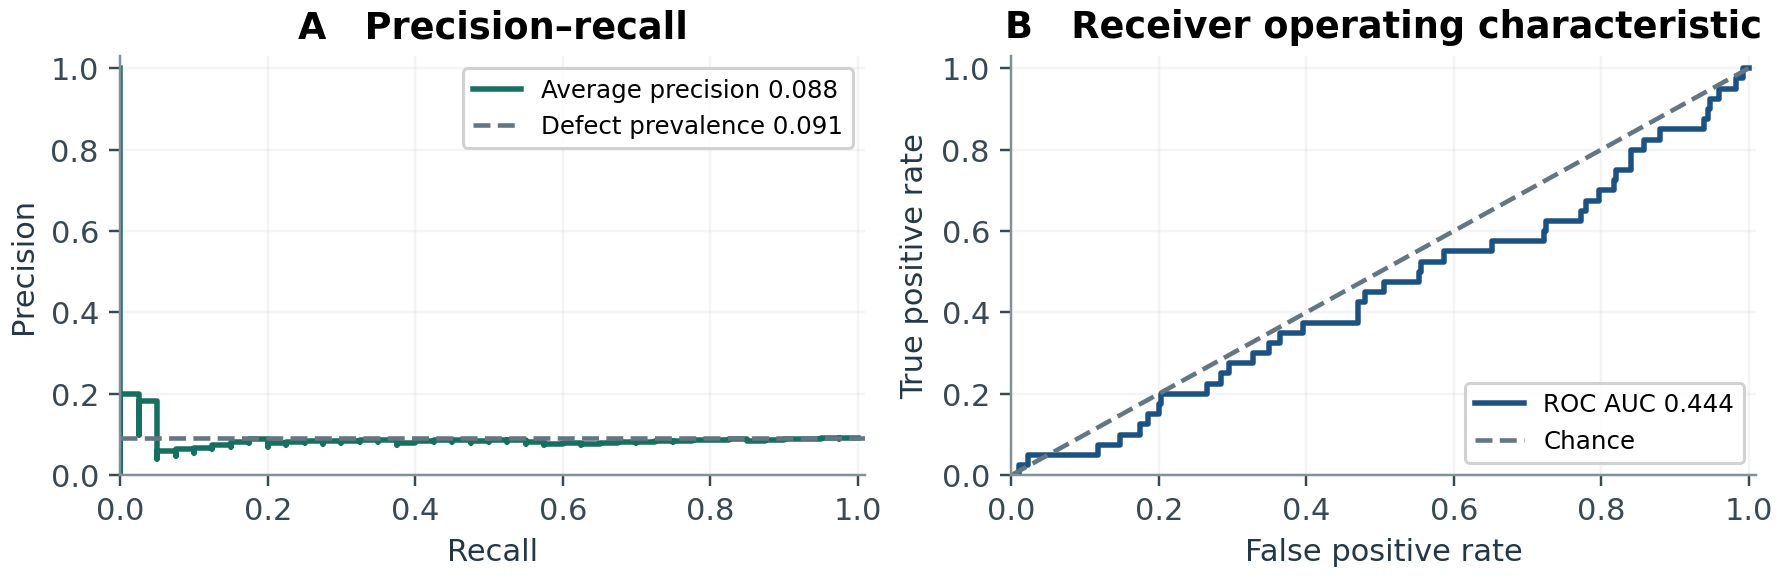

In [8]:
# Figure 2: Final precision–recall and ROC curves
fig, (pr,roc) = plt.subplots(1,2,figsize=(8.1,2.62),layout="constrained")
prec,rec,_=precision_recall_curve(y,score)
pr.step(rec[::-1],prec[::-1],where="pre",lw=1.8,color=green,label=f"Average precision {ap:.3f}")
pr.axhline(y.mean(),color=gray,ls="--",label=f"Defect prevalence {y.mean():.3f}")
pr.set(title="A   Precision–recall",xlabel="Recall",ylabel="Precision")
fpr,tpr,_=roc_curve(y,score)
roc.plot(fpr,tpr,color=blue,lw=1.8,label=f"ROC AUC {auc:.3f}")
roc.plot([0,1],[0,1],"--",color=gray,label="Chance")
roc.set(title="B   Receiver operating characteristic",xlabel="False positive rate",ylabel="True positive rate")
for ax in (pr,roc):
    ax.set(xlim=(0,1.01),ylim=(0,1.03)); ax.legend(frameon=True,framealpha=.9,fontsize=8,loc="upper right" if ax is pr else "lower right"); ax.grid(alpha=.13)
display_figure(fig,"figure_2_precision_recall_roc.png")